# Clustering Workflow

Andrew E. Davidson  
aedavids@ucsc.edu  
9/12/25  

Copyright (c) 2025-2027, Regents of the University of California All rights reserved. https://polyformproject.org/licenses/noncommercial/1.0.0 

Extended Data Figure 3: Unsupervised dimensionality reduction of real clinical plasma cfRNA. samples


normalized Elife, simple unsupervised learning workflow.

1. check for feature where standard deviation == 0
    - Filtering these featues should not effect PCA as they have no predicive value how ever it is suprising that such features exist.
    - out of 76,555 featues 19,283 have a standard deviation close to zero
    - 11,841 are annotated. ie 'ENSG*'
    -  7,442 come from the repeat mask
    - the median values are all close to zero. These features are never expressed

2. center and scale the remaining 57,272 features
    - required: PCA assumes data is centered.
    - recommended if features are on different scales or have different variances. Distance based similarity methods will be dominated by features with large variances
    - TODO
        + does scaling making a difference?
        + does type of scaling matter? ie minmax insteand of standard scaler

3. use PCA to reduce the number of features.
    - PCA compresses data and reduces noise
    - 61 principle components describe 95% of the variance. 
    - number of principle components : 10 total explained variance 83%. Adding an additional pc will only explain > 1% of remaining variance
    - TODO
        + does performance drop signifigantly if we only use best 10 pc?

4. plot 2d cluster results
    * pca, tSNE, k-Means, umap, leiden (scanpy)
    * [scanpy installation](https://scanpy.readthedocs.io/en/stable/installation.html)


In [1]:
from cliUtilities import configLogging
import logging

# rootLogger = configLogging(logLevel="INFO")
rootLogger = configLogging(logLevel="WARN")
logger = logging.getLogger(__name__)

2026-11-21 11:21:15,978 WARNING cliUtilities.py configLogging() line:61] [BEGIN]
2026-11-21 11:21:15,979 WARNING cliUtilities.py configLogging() line:67] [PYTHONPATH : /private/home/aedavids/graceM/src/python:/private/home/aedavids/graceM/src/jupyterNotebooks]
2026-11-21 11:21:15,980 WARNING cliUtilities.py configLogging() line:68] [FILE: /private/home/aedavids/graceM/src/python/cliUtilities.py]
2026-11-21 11:21:15,980 WARNING cliUtilities.py configLogging() line:69] [PWD: /private/home/aedavids/graceM/src/jupyterNotebooks]


In [2]:
from IPython.display import display
from IPython.display import HTML
import matplotlib.pyplot as plt
# set up matplotlib default final artwork complient styles
from plots.plotPanel import natureManuscriptStyle
plt.rcParams.update(natureManuscriptStyle)

import numpy as np
import os
import pandas as pd
from pathlib import Path
import pprint as pp

import scanpy as sc
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler # MinMaxScaler  # LabelEncoder, 
import umap

# local imports
from notebookUtils import  getNotebookName # appendToPYTHONPATH,
from data.loadCounts import loadGenesBySamplesData
from models.scanpyClustering import hyperparameterTunning
from models.scanpyClustering import runScanpy

from plots.plotPanel import combineFiguresLayout, getSubplotWidthAndHeight, Panel
from plots.plotPanel import displayPDFInNotebook
from plots.plotPanel import setFigureFont

from plots.scatterPlots import createScatterPlot
from plots.scatterPlots import pcaScatterPlot
from plots.scatterPlots import plotScatterOnAxis
from plots.scatterPlots import tSNEScatterPlot
from plots.scatterPlots import umapScatterPlot
from plots.plotUtilities import urlify

theMeaningOfLife = 42

/private/home/aedavids/miniconda3/envs/graceM/lib/python3.13/site-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(
/private/home/aedavids/miniconda3/envs/graceM/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
I0000 00:00:1795288881.564322 1850856 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795288881.635908 1850856 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795288883.730531 1850856 cudart_stub.cc:31] Could not find cuda driver

In [3]:
from notebookUtils import getNotebookName

defaultNotebookName="clusteringWorkflow"
notebookName, notebookDir = getNotebookName(defaultNotebookName)
print(f'notebookName: {notebookName}')
print(f'notebookDir: {notebookDir}')
notebookOutDir = f'{notebookDir}/{notebookName}.out'

imgOutDir = f'{notebookOutDir}/img'
os.makedirs(imgOutDir, exist_ok=True)
print(f'imgOutDir: {imgOutDir}')

imgPanelOutDir = f'{imgOutDir}/panel'
os.makedirs(imgPanelOutDir, exist_ok=True)
print(f'imgPanelOutDir : {imgPanelOutDir}')


notebookName: clusteringWorkflow
notebookDir: /private/home/aedavids/graceM/src/jupyterNotebooks
imgOutDir: /private/home/aedavids/graceM/src/jupyterNotebooks/clusteringWorkflow.out/img
imgPanelOutDir : /private/home/aedavids/graceM/src/jupyterNotebooks/clusteringWorkflow.out/img/panel


In [4]:
from matplotlib.axes import Axes

def saveFigure(fig : plt.figure, 
               ax1 : Axes,
               ax2 : Axes,
               title1: str, title2: str,
               outDirArg : str,  prefix : str = "") -> list[str]:
    ''' 
    8/11/2026
    This is hacked up version of src/python/archive/archiveUtilities.py saveFigure()
    The original version assume you wanted to save a figure. We create a figure with two
    subplots. For our manuscript we want to save the subplots separately
    
    
    save PNG and PDF versions files in a consistent way
    
    
    arguments:
        title:
            there are several ways the title could be set
            It is not clear how to get the title in a consistent way
            the output file name will be a URL safe version of the title  
            
            
    returns list of output file paths
    '''
    os.makedirs(outDirArg, exist_ok=True)
    fileName1 = urlify(prefix + "_" + title1).strip()
    outPathPNG1 = f'{outDirArg}/{fileName1}.png'
    outPathPDF1 = f'{outDirArg}/{fileName1}.pdf'
    
    fileName2 = urlify(prefix + "_" + title2).strip()
    outPathPNG2 = f'{outDirArg}/{fileName2}.png'
    outPathPDF2 = f'{outDirArg}/{fileName2}.pdf'
    
    fig.canvas.draw()

    bbox1 = ax1.get_tightbbox(fig.canvas.get_renderer())
    bbox2 = ax2.get_tightbbox(fig.canvas.get_renderer())

    # fig.savefig(
    #     "subplot1.png",
    #     bbox_inches=bbox1.transformed(fig.dpi_scale_trans.inverted())
    # )


    # bbox_inches="tight" reduces extra whitespace
    #  if clipping try adding pad_inches=0.1 to leave a bit of breathing room:
    # facecolor="white", sets the background color
    # transparent=True, 
    #   In a PNG, this means the alpha channel is set to 0 (clear).
    #   In a PDF/SVG, it means no opaque rectangle is drawn behind your plot.
    logger.warning(f'AEDWIP 8/5/26 changed code to save png and pdf check file names and types')
    # fig.savefig(outPathPNG, bbox_inches="tight",  dpi=300 )
    # logger.warning(f"saved : {outPathPNG}")
    
    fig.savefig(outPathPNG1, dpi=300, 
                bbox_inches=bbox1.transformed( fig.dpi_scale_trans.inverted() )
                )
    fig.savefig(outPathPDF1, dpi=300, 
                bbox_inches=bbox1.transformed( fig.dpi_scale_trans.inverted() )
                )
     
    fig.savefig(outPathPNG2, dpi=300, 
                bbox_inches=bbox2.transformed( fig.dpi_scale_trans.inverted() )
                )
    fig.savefig(outPathPDF2, dpi=300, 
                bbox_inches=bbox2.transformed( fig.dpi_scale_trans.inverted() )
                )
     
    
    # fig.savefig(outPathPDF, bbox_inches="tight",  dpi=300 )
    # logger.warning(f"saved : {outPathPDF}")

    
    # to maintain backwards compatiblity only the PNG path is returned
    return [outPathPNG1, outPathPNG2, outPathPDF1, outPathPDF2]

In [5]:
# we want the diagnosis to be colored in a consistent way

diagnosisColors: dict[str, str] = {
    "Healthy_donor": "#440154",
    "Colorectal_Cancer": "#414487",
    "Esophagus_Cancer": "#2A788E",
    "Liver_Cancer": "#22A884",
    "Lung_Cancer": "#7AD151",
    "Stomach_Cancer": "#FDE725",
}

## Load Data

In [6]:
realDataRoot = "/private/groups/kimlab/data/elife"
realDataPath = f'{realDataRoot}/elife_all_norm_counts_2023-05-18.csv'
realMetaDataPath = f'{realDataRoot}/elife_scaled_metaData_2023-05-18.csv'

In [7]:
realMetaDF = pd.read_csv(realMetaDataPath)
realYSeries = realMetaDF["diagnosis"]
print(f'realYSeries.shape : {realYSeries.shape}')

originalDiagnosesNP = realMetaDF["diagnosis"].unique()
realMetaDF["diagnosis"] = realMetaDF["diagnosis"].str.replace(" ", "_")

print( f'\nrealMetaDF.shape : {realMetaDF.shape}')
diagnosesNP= realMetaDF.loc[:, 'diagnosis'].unique()

print(f'\noriginalDiagnosesNP : {originalDiagnosesNP}')
print(f'diagnosesNP         : {diagnosesNP}')

realYSeries.shape : (224,)

realMetaDF.shape : (224, 16)

originalDiagnosesNP : <StringArray>
[ 'Esophagus Cancer',       'Lung Cancer',      'Liver Cancer',
    'Stomach Cancer', 'Colorectal Cancer',     'Healthy donor']
Length: 6, dtype: str
diagnosesNP         : <StringArray>
[ 'Esophagus_Cancer',       'Lung_Cancer',      'Liver_Cancer',
    'Stomach_Cancer', 'Colorectal_Cancer',     'Healthy_donor']
Length: 6, dtype: str


In [8]:
realXDF, realYSeries = loadGenesBySamplesData( 
           originalDiagnosesNP, 
           realDataPath, 
           realMetaDataPath,
           yCategoryColName = 'diagnosis',
           yRowIdName = 'sample_id')

print(f'\nrealXDF.shape : {realXDF.shape}')
print(f'realXDF.iloc[0:5, 0:4] :\n{realXDF.iloc[0:5, 0:4]}')

2026-11-21 11:21:29,007 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/data/elife/elife_all_norm_counts_2023-05-18.csv]
2026-11-21 11:21:30,110 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/data/elife/elife_scaled_metaData_2023-05-18.csv]



realXDF.shape : (224, 76555)
realXDF.iloc[0:5, 0:4] :
gene                (A)n  (AAA)n  (AAAAAAC)n  (AAAAAAG)n
sampleIds                                               
SRR14506659   201.672053     0.0         0.0         0.0
SRR14506660   110.450773     0.0         0.0         0.0
SRR14506661  3722.776395     0.0         0.0         0.0
SRR14506662  1394.605651     0.0         0.0         0.0
SRR14506663  2843.473730     0.0         0.0         0.0


## Preprocess Data

1. find, explore and filter out features that have zero standard deviation
2. center and scale data and reduce the number of dimensions
3. use PCA to reduce the number of features

In [9]:
byColumns = 0
stdSeries = realXDF.std(axis=byColumns)
print(f'stdSeries.shape : {stdSeries.shape}')

selectColsWithZereoStd = np.isclose(stdSeries, 0.0)
print(f'number of featues with std close to zero : {sum(selectColsWithZereoStd)}')

stdSeries.shape : (76555,)
number of featues with std close to zero : 19283


In [10]:
colsWithZeroStdIndex = realXDF.columns[selectColsWithZereoStd]
print(f'columns with zero std shape : {colsWithZeroStdIndex.shape}')

annotatedFeatureIndex = colsWithZeroStdIndex[ colsWithZeroStdIndex.str.contains('ENSG')]
print(f'columns with annotated featureIndex shape : {annotatedFeatureIndex.shape}')

columns with zero std shape : (19283,)
columns with annotated featureIndex shape : (7442,)


In [11]:
# is the expected value zero?
zeroStdDF = realXDF.loc[:, colsWithZeroStdIndex]
print(f'zeroStdDF.shape            : {zeroStdDF.shape}')

zeroStdMedianSeries = zeroStdDF.median()
print(f'zeroStdMedianSeries.shape  : {zeroStdMedianSeries.shape}')

medianNotCloseToZero = ~np.isclose(zeroStdMedianSeries, 0.0)
print(f'medianNotCloseToZero.shape : {medianNotCloseToZero.shape}')


zeroStdDF.shape            : (224, 19283)
zeroStdMedianSeries.shape  : (19283,)
medianNotCloseToZero.shape : (19283,)


In [12]:
filteredXDF = realXDF.loc[:, ~selectColsWithZereoStd] 
print(f'filteredXDF.shape : {filteredXDF.shape}')

filteredXDF.shape : (224, 57272)


2. center and scale data and reduce the number of dimensions

In [13]:
standardScaler = StandardScaler()
scaledXNP = standardScaler.fit_transform(filteredXDF)
print(f'scaledXNP.shape : {scaledXNP.shape}')

scaledXNP.shape : (224, 57272)


3. use PCA to reduce the number of features

In [14]:
# find the number of components that describes 95% of the variance
accountForVariance = 0.95
pca = PCA( n_components=accountForVariance, random_state=42)

principalComponentsNP = pca.fit_transform(scaledXNP)
print(f'principalComponentsNP.shape {principalComponentsNP.shape}')
print(f'{principalComponentsNP.shape[1]} components account for {accountForVariance}% of the variance')

principalComponentsNP.shape (224, 61)
61 components account for 0.95% of the variance


In [15]:
def findBestPrincipleComponents(pca: PCA,
                                principalComponents : np.array
                                ) -> tuple[np.array, float] :
    '''
    at some points we get diminising returns from using more principle components.
    Find the set of principle components such that adding another component
    explains less than 1% of the remaining variance in the data
    
    arguments:
        pca after calling fit()
        
        principalComponents
            np array returned by pca.transform()
        
    '''
    # selectBestPCIndex is boolean array
    # explained_variance_ratio_ is in descending order
    selectBestPCIndex = pca.explained_variance_ratio_ >= 0.01
    # print(selectBestPCIndex.shape)
    # print(selectBestPCIndex[8:12])
    bestPCs = principalComponents[:,selectBestPCIndex]
    #print(bestPCs.shape)
    
    # numPC is the number of PC that explain more than 1% of the variance
    numPC = bestPCs.shape[1]
    explainedVariance = pca.explained_variance_ratio_.cumsum()[numPC]
    
    return(bestPCs, explainedVariance)


bestPCs, explainedVariance = findBestPrincipleComponents(pca, principalComponentsNP)
print(f'number of principle components : {bestPCs.shape[1]} total explained variance {explainedVariance*100:.2f}%')
# bestPCs

number of principle components : 10 total explained variance 83.43%


## PCA Plots

2026-11-21 11:21:33,980 WARNING 3893787985.py saveFigure() line:53] [AEDWIP 8/5/26 changed code to save png and pdf check file names and types]


saved : /private/home/aedavids/graceM/src/jupyterNotebooks/clusteringWorkflow.out/img/_elife-n-224-PCA-n-61-accounts-for-9500-of-variance-jitter100.png
saved : /private/home/aedavids/graceM/src/jupyterNotebooks/clusteringWorkflow.out/img/_elife-n-224-PCA-n-10-accounts-for-8343-of-variance-jitter100.png
saved : /private/home/aedavids/graceM/src/jupyterNotebooks/clusteringWorkflow.out/img/_elife-n-224-PCA-n-61-accounts-for-9500-of-variance-jitter100.pdf
saved : /private/home/aedavids/graceM/src/jupyterNotebooks/clusteringWorkflow.out/img/_elife-n-224-PCA-n-10-accounts-for-8343-of-variance-jitter100.pdf


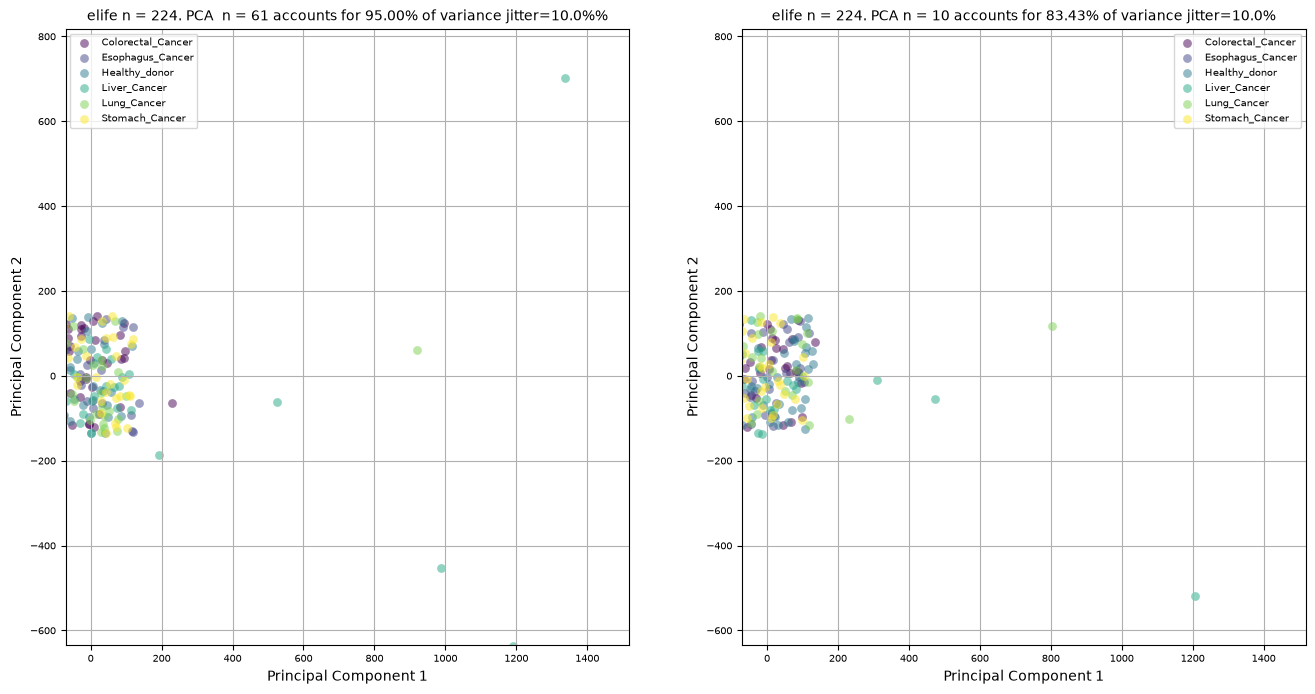

In [16]:
def runPlotPCA(
                leftPC : np.array,
                rightPC : np.array
        ) -> tuple[plt.Figure, plt.axis, plt.axis] :
        '''
        create 2 plots on the same figure. One using leftPC and rightPC
        
        wrapped this to avoid global polution
        '''
        fig, tup = plt.subplots(1, 2, figsize=(16, 8))
        ax1, ax2 = tup
        markerSize = 40
        jitterFrac = 0.1 # 10%

        titleAx1 = f'elife n = {len(realYSeries)}. PCA  n = {leftPC.shape[1]} accounts for {accountForVariance*100:0.2F}% of variance'
        ax1Jiter = f'jitter={jitterFrac:0.1%}%'
        titleAx1 = f'{titleAx1} {ax1Jiter}'
        #print(f'{titleAx1}')

        pcaScatterPlot( 
                data=leftPC, 
                ySeries=realYSeries,  
                panel=ax1,
                title=titleAx1,
                markerSize=markerSize,
                jitterFrac=jitterFrac
                )

        titleAx2 = f'elife n = {len(realYSeries)}. PCA n = {rightPC.shape[1]} accounts for {explainedVariance*100:0.2F}% of variance'
        ax2Jiter = f'jitter={jitterFrac:0.1%}'
        titleAx2 = (f'{titleAx2} {ax2Jiter}')
        #print(f'{titleAx2}')

        pcaScatterPlot( 
                data=rightPC, 
                ySeries=realYSeries,  
                panel=ax2,
                title=titleAx2,
                markerSize=markerSize,
                jitterFrac=jitterFrac
                )
        
        return (fig, ax1, ax2)

t = runPlotPCA(principalComponentsNP, bestPCs)

def savePCA(t):
    pcaFig, pcaLeftAxes, pcaRightAxes = t

    pcaTitle1 = pcaLeftAxes.get_title()
    pcaTitle2 = pcaRightAxes.get_title()
    pcaPlotPath = saveFigure(pcaFig, pcaLeftAxes, pcaRightAxes, pcaTitle1, pcaTitle2, imgOutDir)
    for p in pcaPlotPath:
        print(f'saved : {p}')
        
savePCA(t)

## UMAP Plots

In [17]:
# principleComponentNP = pca( scaled centered data) that expained 95% of variance
reducerPrincipleComponents = umap.UMAP(n_components=2, random_state=theMeaningOfLife)
UMAPEmbeddingPrincipleComponentsNP = reducerPrincipleComponents.fit_transform(principalComponentsNP)

# bestPCs is a subset of principleComponentNP that explains 83% of variance
reducerBestPCs = umap.UMAP(n_components=2, random_state=theMeaningOfLife)
UMAPEmbeddingBestPCsNP = reducerBestPCs.fit_transform(bestPCs)

/private/home/aedavids/miniconda3/envs/graceM/lib/python3.13/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/private/home/aedavids/miniconda3/envs/graceM/lib/python3.13/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/private/home/aedavids/miniconda3/envs/graceM/lib/python3.13/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) n

In [18]:
print(type(UMAPEmbeddingPrincipleComponentsNP))
UMAPEmbeddingPrincipleComponentsNP.shape

<class 'numpy.ndarray'>


(224, 2)

2026-11-21 11:21:47,982 WARNING 3893787985.py saveFigure() line:53] [AEDWIP 8/5/26 changed code to save png and pdf check file names and types]


saved : /private/home/aedavids/graceM/src/jupyterNotebooks/clusteringWorkflow.out/img/_elife-n-224-UMAP-n-2-jitter00.png
saved : /private/home/aedavids/graceM/src/jupyterNotebooks/clusteringWorkflow.out/img/_elife-n-224-UMAP-n-2-jitter00aedwip.png
saved : /private/home/aedavids/graceM/src/jupyterNotebooks/clusteringWorkflow.out/img/_elife-n-224-UMAP-n-2-jitter00.pdf
saved : /private/home/aedavids/graceM/src/jupyterNotebooks/clusteringWorkflow.out/img/_elife-n-224-UMAP-n-2-jitter00aedwip.pdf


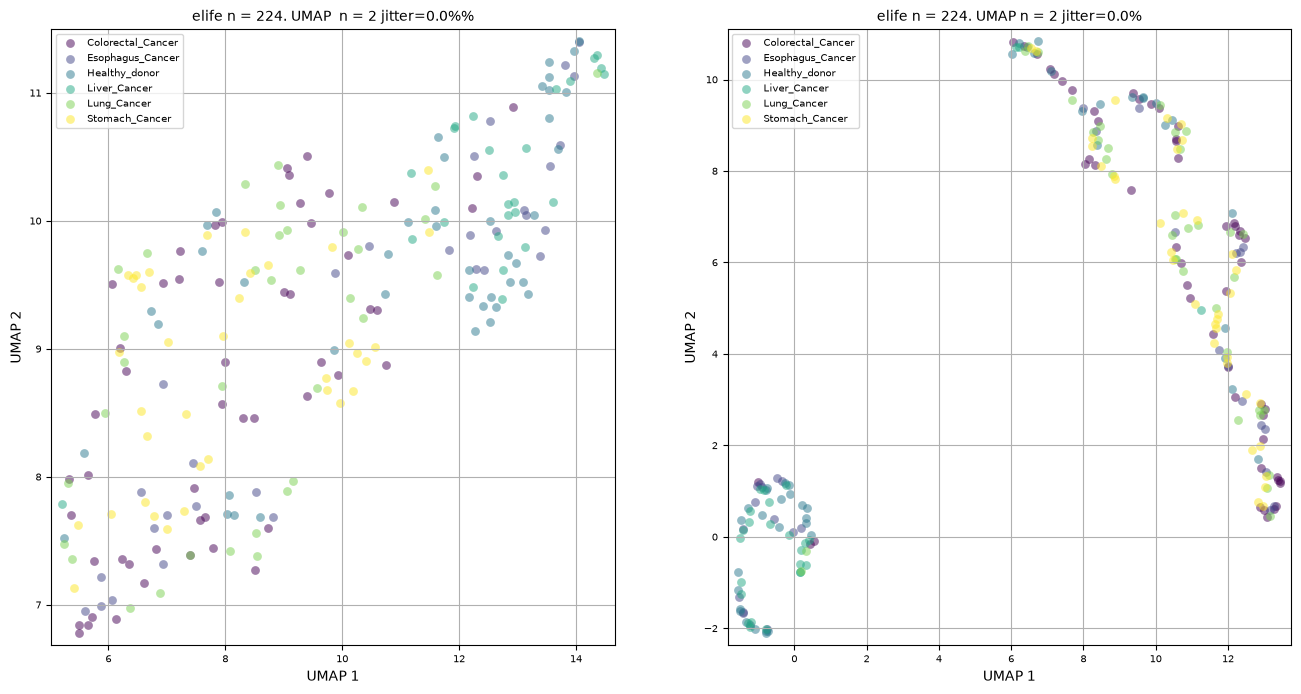

In [19]:
def umapPlots(leftPC : np.array,
                rightPC : np.array ) -> tuple[plt.Figure, plt.axis, plt.axis] :
    ''' 
    create 2 plots on the same figure. One using leftPC and rightPC
        
    wrapper to prevent global polution
    '''
    fig, tup = plt.subplots(1, 2, figsize=(16, 8))
    ax1, ax2 = tup
    markerSize = 40
    jitterFrac = 0 # 0.01 # 1%

    titleAx1 = f'elife n = {len(realYSeries)}. UMAP  n = {leftPC.shape[1]}'
    ax1Jiter = f'jitter={jitterFrac:0.1%}%'
    titleAx1 = f'{titleAx1} {ax1Jiter}'
    #print(f'{titleAx1}')

    umapScatterPlot( 
        data=leftPC, 
        ySeries=realYSeries,  
        panel=ax1,
        title=titleAx1,
        markerSize=markerSize,
        jitterFrac=jitterFrac
        )

    titleAx2 = f'elife n = {len(realYSeries)}. UMAP n = {rightPC.shape[1]}'
    ax2Jiter = f'jitter={jitterFrac:0.1%}'
    titleAx2 = (f'{titleAx2} {ax2Jiter}')
    #print(f'{titleAx2}')

    umapScatterPlot( 
        data=rightPC, 
        ySeries=realYSeries,  
        panel=ax2,
        title=titleAx2,
        markerSize=markerSize,
        jitterFrac=jitterFrac
        )
    
    return (fig, ax1, ax2)

t = umapPlots(UMAPEmbeddingPrincipleComponentsNP, UMAPEmbeddingBestPCsNP)

def saveUMAP(t):
    umapFig, umapLeftAxes, umapRightAxes = t

    umapTitle1 = umapLeftAxes.get_title()
    umapTitle2 = umapRightAxes.get_title() + "aedwip"
    pcaPlotPath = saveFigure(umapFig, umapLeftAxes, umapRightAxes, umapTitle1, umapTitle2, imgOutDir)
    for p in pcaPlotPath:
        print(f'saved : {p}')
        
saveUMAP(t)

## t-SNE (t-distributed Stochastic Neighbor Emdedding)

In [20]:
%%time

# principleComponentNP = pca( scaled centered data) that expained 95% of variance
tsneEmbeddd = TSNE( n_components=2, random_state=theMeaningOfLife)
TSNE_PrincipalComponentsNP = tsneEmbeddd.fit_transform(principalComponentsNP)

# bestPCs is a subset of principleComponentNP that explains 83% of variance
tsneEmbeddd = TSNE( n_components=2, random_state=theMeaningOfLife)
TSNE_BestPCsNP = tsneEmbeddd.fit_transform(bestPCs)

CPU times: user 1min 39s, sys: 5.32 s, total: 1min 44s
Wall time: 1.47 s


2026-11-21 11:21:51,606 WARNING 3893787985.py saveFigure() line:53] [AEDWIP 8/5/26 changed code to save png and pdf check file names and types]


saved : /private/home/aedavids/graceM/src/jupyterNotebooks/clusteringWorkflow.out/img/_elife-n-224-tSNE-n-61-jitter100.png
saved : /private/home/aedavids/graceM/src/jupyterNotebooks/clusteringWorkflow.out/img/_elife-n-224-tSNE-n-10-jitter100.png
saved : /private/home/aedavids/graceM/src/jupyterNotebooks/clusteringWorkflow.out/img/_elife-n-224-tSNE-n-61-jitter100.pdf
saved : /private/home/aedavids/graceM/src/jupyterNotebooks/clusteringWorkflow.out/img/_elife-n-224-tSNE-n-10-jitter100.pdf


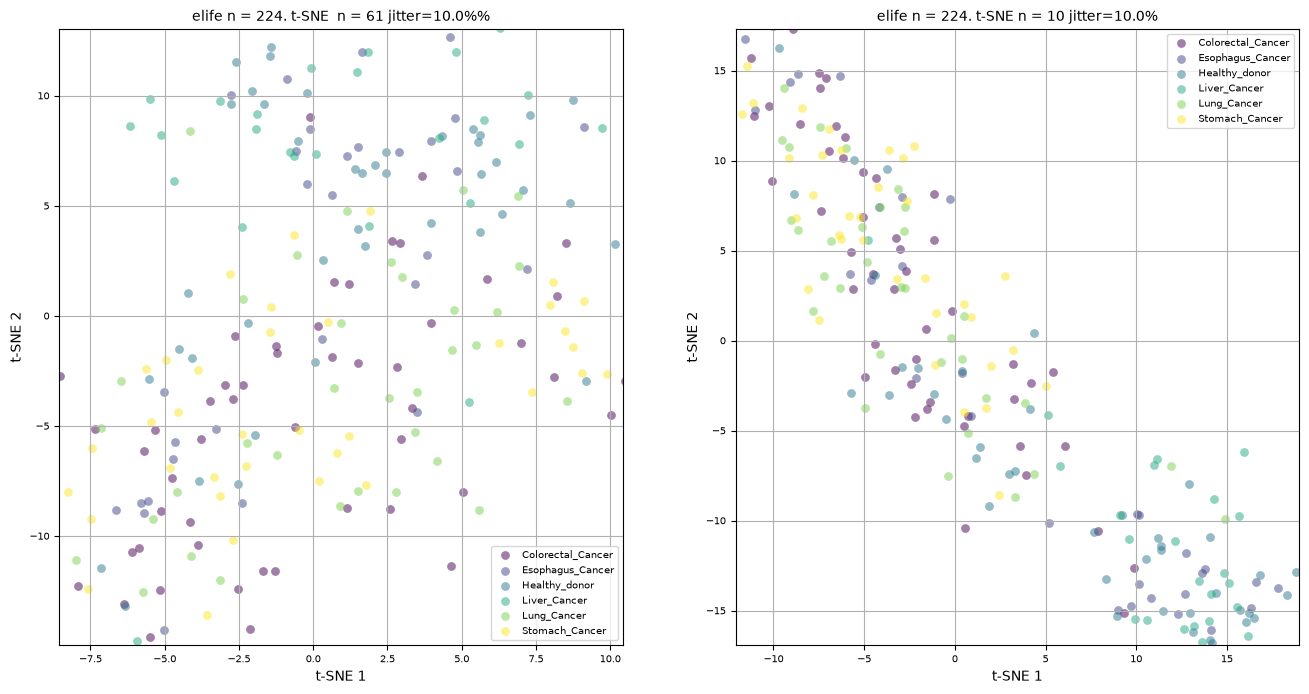

In [21]:
def tSNEPlots(leftPC : np.array,
                rightPC : np.array ) -> tuple[plt.Figure, plt.axis, plt.axis] :
    ''' 
    wrapper to prevent global polution
    '''
    fig, tup = plt.subplots(1, 2, figsize=(16, 8))
    ax1, ax2 = tup
    markerSize = 40
    jitterFrac = 0.1 # 10%

    titleAx1 = f'elife n = {len(realYSeries)}. t-SNE  n = {principalComponentsNP.shape[1]}'
    ax1Jiter = f'jitter={jitterFrac:0.1%}%'
    titleAx1 = f'{titleAx1} {ax1Jiter}'
    #print(f'{titleAx1}')

    tSNEScatterPlot ( 
        data=leftPC, 
        ySeries=realYSeries,  
        panel=ax1,
        title=titleAx1,
        markerSize=markerSize,
        jitterFrac=jitterFrac
        )

    titleAx2 = f'elife n = {len(realYSeries)}. t-SNE n = {bestPCs.shape[1]}'
    ax2Jiter = f'jitter={jitterFrac:0.1%}'
    titleAx2 = (f'{titleAx2} {ax2Jiter}')
    #print(f'{titleAx2}')

    tSNEScatterPlot ( 
        data=rightPC, 
        ySeries=realYSeries,  
        panel=ax2,
        title=titleAx2,
        markerSize=markerSize,
        jitterFrac=jitterFrac
        )
    
    return( fig, ax1, ax2 )

t = tSNEPlots(TSNE_PrincipalComponentsNP, TSNE_BestPCsNP)

def savetSNE(t) :
    tSNEFig, tSNELeftAxes, tSNERightAxes = t

    tSNETitle1 = tSNELeftAxes.get_title()
    tSNETitle2 = tSNERightAxes.get_title() 
    tSNEPlotPath = saveFigure(tSNEFig, tSNELeftAxes, tSNERightAxes, tSNETitle1, tSNETitle2, imgOutDir)
    for p in tSNEPlotPath:
        print(f'saved : {p}')
        
savetSNE(t)

## K-means clustering. 6 centeroids
<span style="color:red">does not work</span>

In [22]:
%%time
n_clusters = 6
# principleComponentNP = pca( scaled centered data) that expained 95% of variance
kmeansPC = KMeans(n_clusters=n_clusters, random_state=theMeaningOfLife).fit(principalComponentsNP)

# bestPCs is a subset of principleComponentNP that explains 83% of variance
kmeansBest = KMeans(n_clusters=n_clusters, random_state=theMeaningOfLife).fit(bestPCs)
print(type(kmeansBest))

<class 'sklearn.cluster._kmeans.KMeans'>
CPU times: user 300 ms, sys: 22.6 ms, total: 323 ms
Wall time: 8.92 ms


In [23]:
def evaluateKMeans(kmeans):
    kpcDF = pd.DataFrame({
        "clusterId" : kmeans.labels_,
        "label" : realYSeries,
        "count" : range(len(realYSeries))
    })

    xxxDF = kpcDF.groupby(['clusterId', 'label']).count()
    display(xxxDF)
    xxxDF.loc[:, 'count'].sum()

print(f'ground true labels')
display( realYSeries.groupby( realYSeries ).size() )

print(f"\nkmeansPC  {principalComponentsNP.shape[1]} Principle components groupby(['label', 'clusterId']).count()")
evaluateKMeans(kmeansPC)

print(f"\nkmeansBest {bestPCs.shape[1]} Principle components groupby(['label', 'clusterId']).count()")
evaluateKMeans(kmeansBest)

ground true labels


diagnosis
Colorectal_Cancer    53
Esophagus_Cancer     31
Healthy_donor        43
Liver_Cancer         26
Lung_Cancer          35
Stomach_Cancer       36
Name: diagnosis, dtype: int64


kmeansPC  61 Principle components groupby(['label', 'clusterId']).count()


count
clusterId label                   
0         Liver_Cancer           4
1         Liver_Cancer           2
2         Lung_Cancer            1
3         Colorectal_Cancer     52
          Esophagus_Cancer      31
          Healthy_donor         43
          Liver_Cancer          16
          Lung_Cancer           34
          Stomach_Cancer        36
4         Colorectal_Cancer      1
          Liver_Cancer           3
5         Liver_Cancer           1


kmeansBest 10 Principle components groupby(['label', 'clusterId']).count()


count
clusterId label                   
0         Colorectal_Cancer      3
          Esophagus_Cancer      15
          Healthy_donor         24
          Liver_Cancer          20
          Lung_Cancer            1
1         Liver_Cancer           1
2         Lung_Cancer            1
3         Liver_Cancer           1
4         Colorectal_Cancer     50
          Esophagus_Cancer      16
          Healthy_donor         19
          Liver_Cancer           3
          Lung_Cancer           33
          Stomach_Cancer        36
5         Liver_Cancer           1

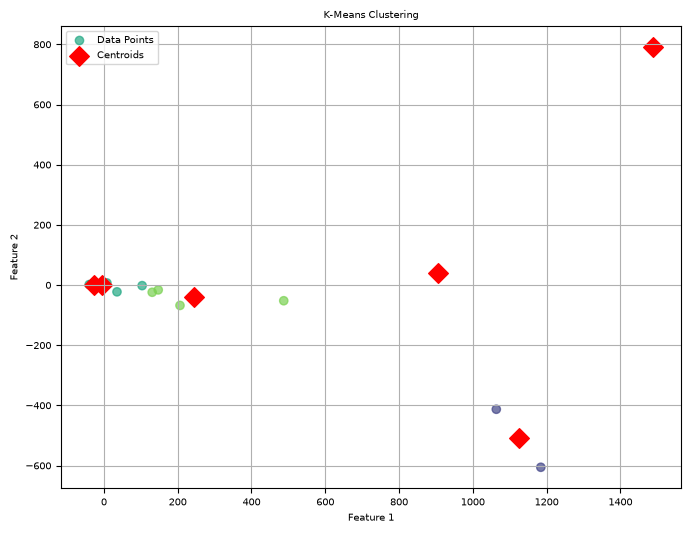

In [24]:
def kMeansPlots(data, kmeans):
    labels = kmeans.labels_
    centroids = kmeans.cluster_centers_

    # Prepare data for plotting
    xs = data[:, 0]
    ys = data[:, 1]
    centroids_x = centroids[:, 0]
    centroids_y = centroids[:, 1]

    # Plot the clusters and centroids
    plt.figure(figsize=(8, 6))
    plt.scatter(xs, ys, c=labels, cmap='viridis', alpha=0.7, label='Data Points')
    plt.scatter(centroids_x, centroids_y, marker='D', s=100, color='red', label='Centroids')
    plt.title('K-Means Clustering')
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.legend()
    plt.grid(True)
    
pca2d = PCA( n_components=2, random_state=42)
pcNP = pca2d.fit_transform( principalComponentsNP)
kMeansPlots( pcNP, kmeansPC)
# kMeansPlots( bestPCs[:,0:2], kmeansBest)

##  Scanpy Louvain/ leiden Clustering

In [25]:
# (optional) nicer logging
sc.settings.verbosity = 2

scampyImgOutDir = f'{imgOutDir}/scanpy'
os.makedirs(scampyImgOutDir, exist_ok=True)
print(f'scampyImgOutDir: {scampyImgOutDir}')

sc.settings.figdir = scampyImgOutDir  # where to save figures with save=...
sc.set_figure_params(figsize=(5, 5), dpi=120)

scampyImgOutDir: /private/home/aedavids/graceM/src/jupyterNotebooks/clusteringWorkflow.out/img/scanpy


computing neighbors


/private/home/aedavids/graceM/src/python/models/scanpyClustering.py:151: FutureWarning: The argument use_rep is deprecated and will be removed in the future. Use `use` instead.
  sc.pp.neighbors(adata, use_rep="X_pca", n_neighbors=nNeighbors, n_pcs=None)


    finished (0:00:02)
running Leiden clustering


/private/home/aedavids/graceM/src/python/models/scanpyClustering.py:164: FutureWarning: The argument key_added is deprecated and will be removed in the future. Use `out` instead.
  sc.tl.leiden(adata, resolution=resolution, key_added="leiden")
/private/home/aedavids/miniconda3/envs/graceM/lib/python3.13/site-packages/scverse_misc/_deprecated/__init__.py:117: FutureWarning: The `igraph` and `networkit` implementations of leiden clustering are *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' or 'networkit' to use them.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`.
  return func(*args, **kwargs)


    finished (0:00:00)
computing UMAP
    finished (0:00:00)
saved /private/home/aedavids/graceM/src/jupyterNotebooks/clusteringWorkflow.out/img/scanpy/leidenUMAP.pdf
saved /private/home/aedavids/graceM/src/jupyterNotebooks/clusteringWorkflow.out/img/scanpy/leidenUMAPLabel.pdf
saved /private/home/aedavids/graceM/src/jupyterNotebooks/clusteringWorkflow.out/img/scanpy/2PlotleidenUMAPLabelFirst.pdf
saved /private/home/aedavids/graceM/src/jupyterNotebooks/clusteringWorkflow.out/img/scanpy/2PlotleidenUMAPLabelSecond.pdf


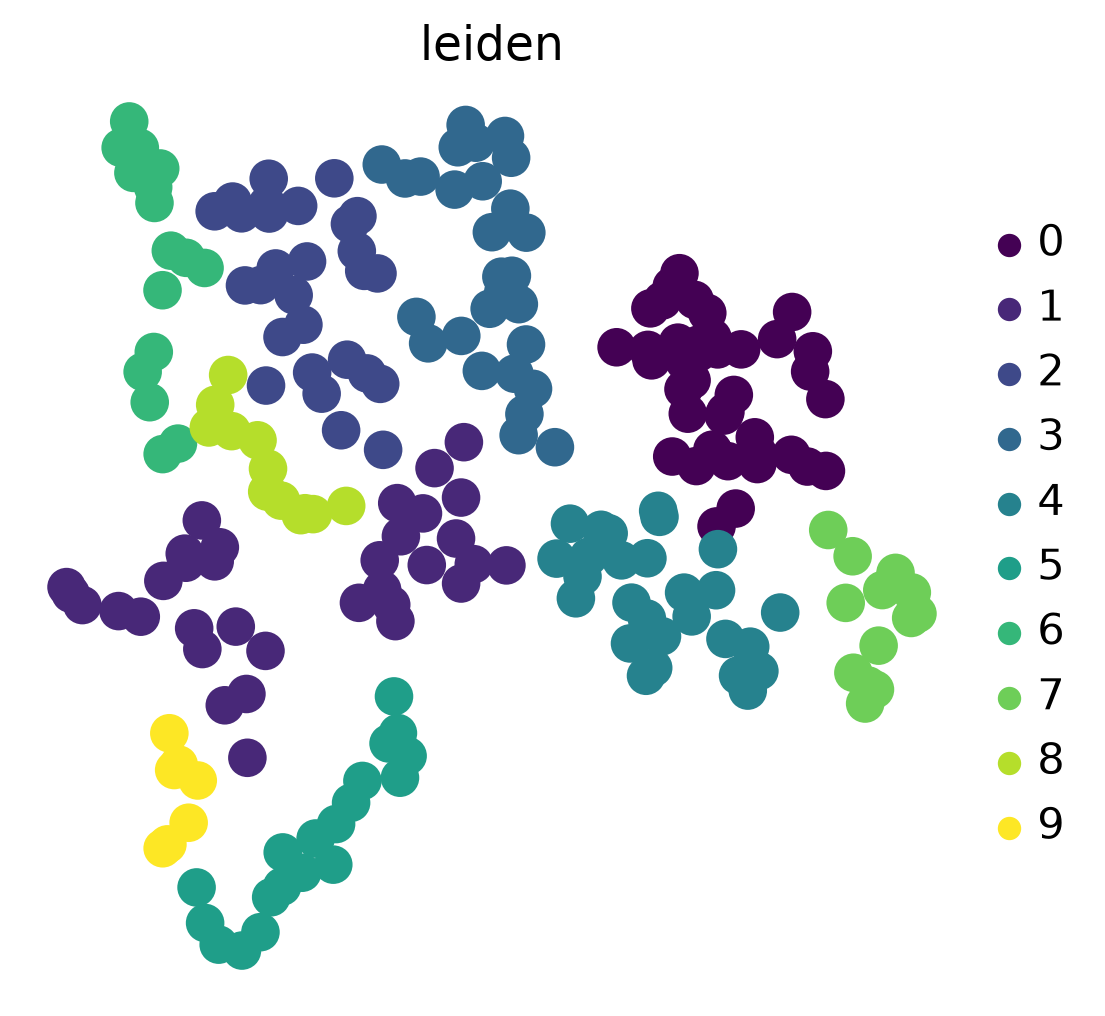

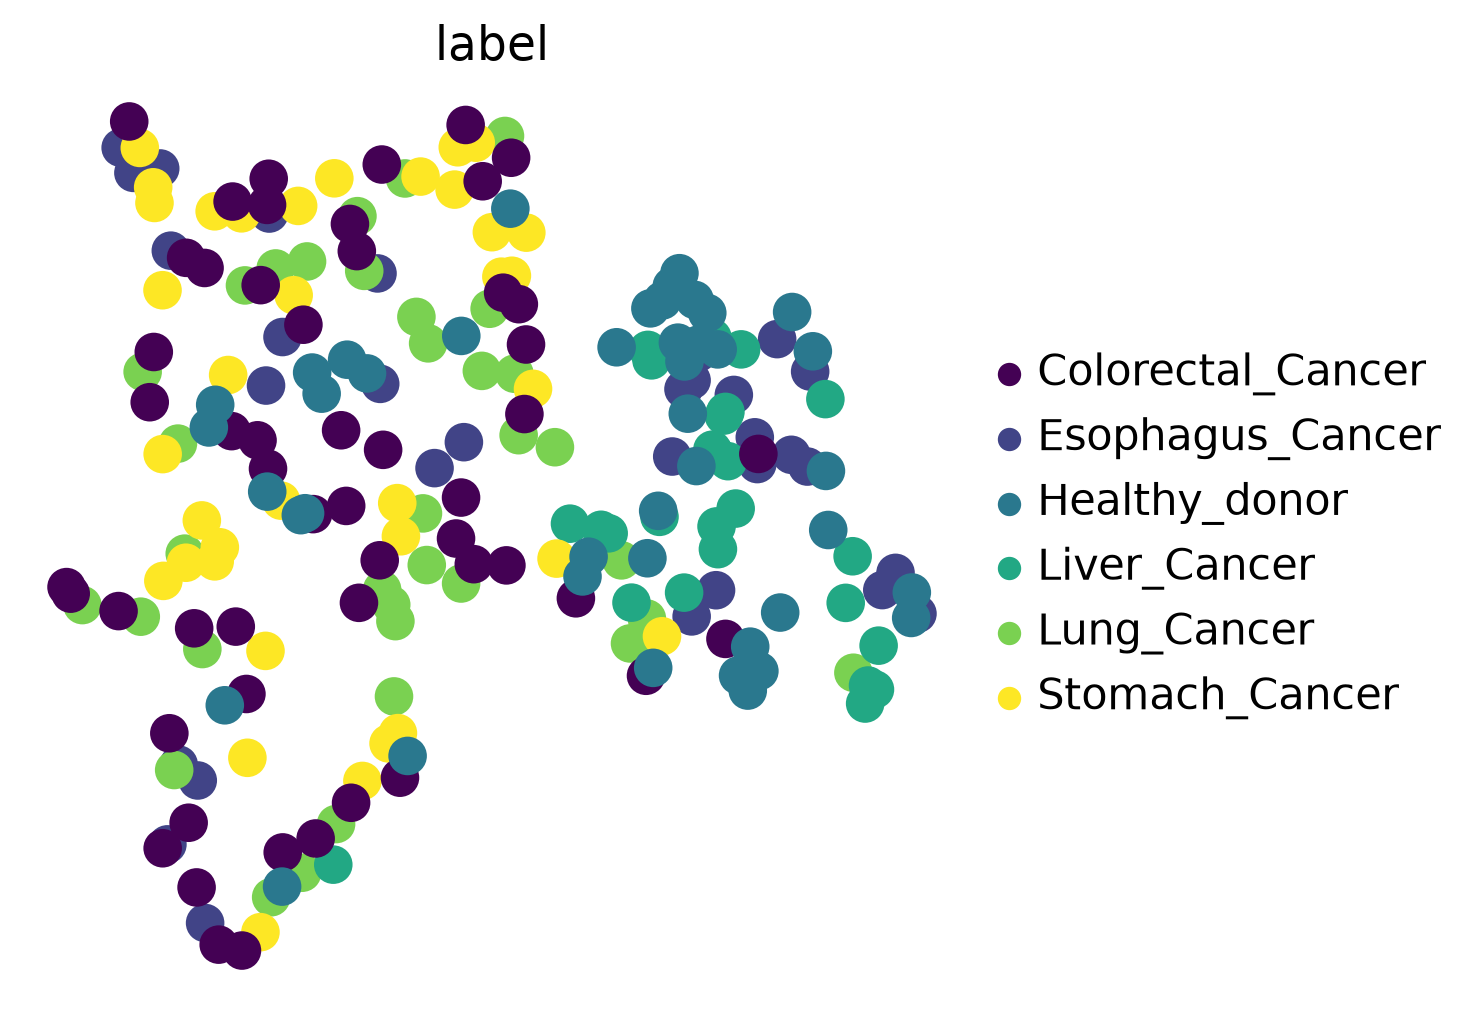

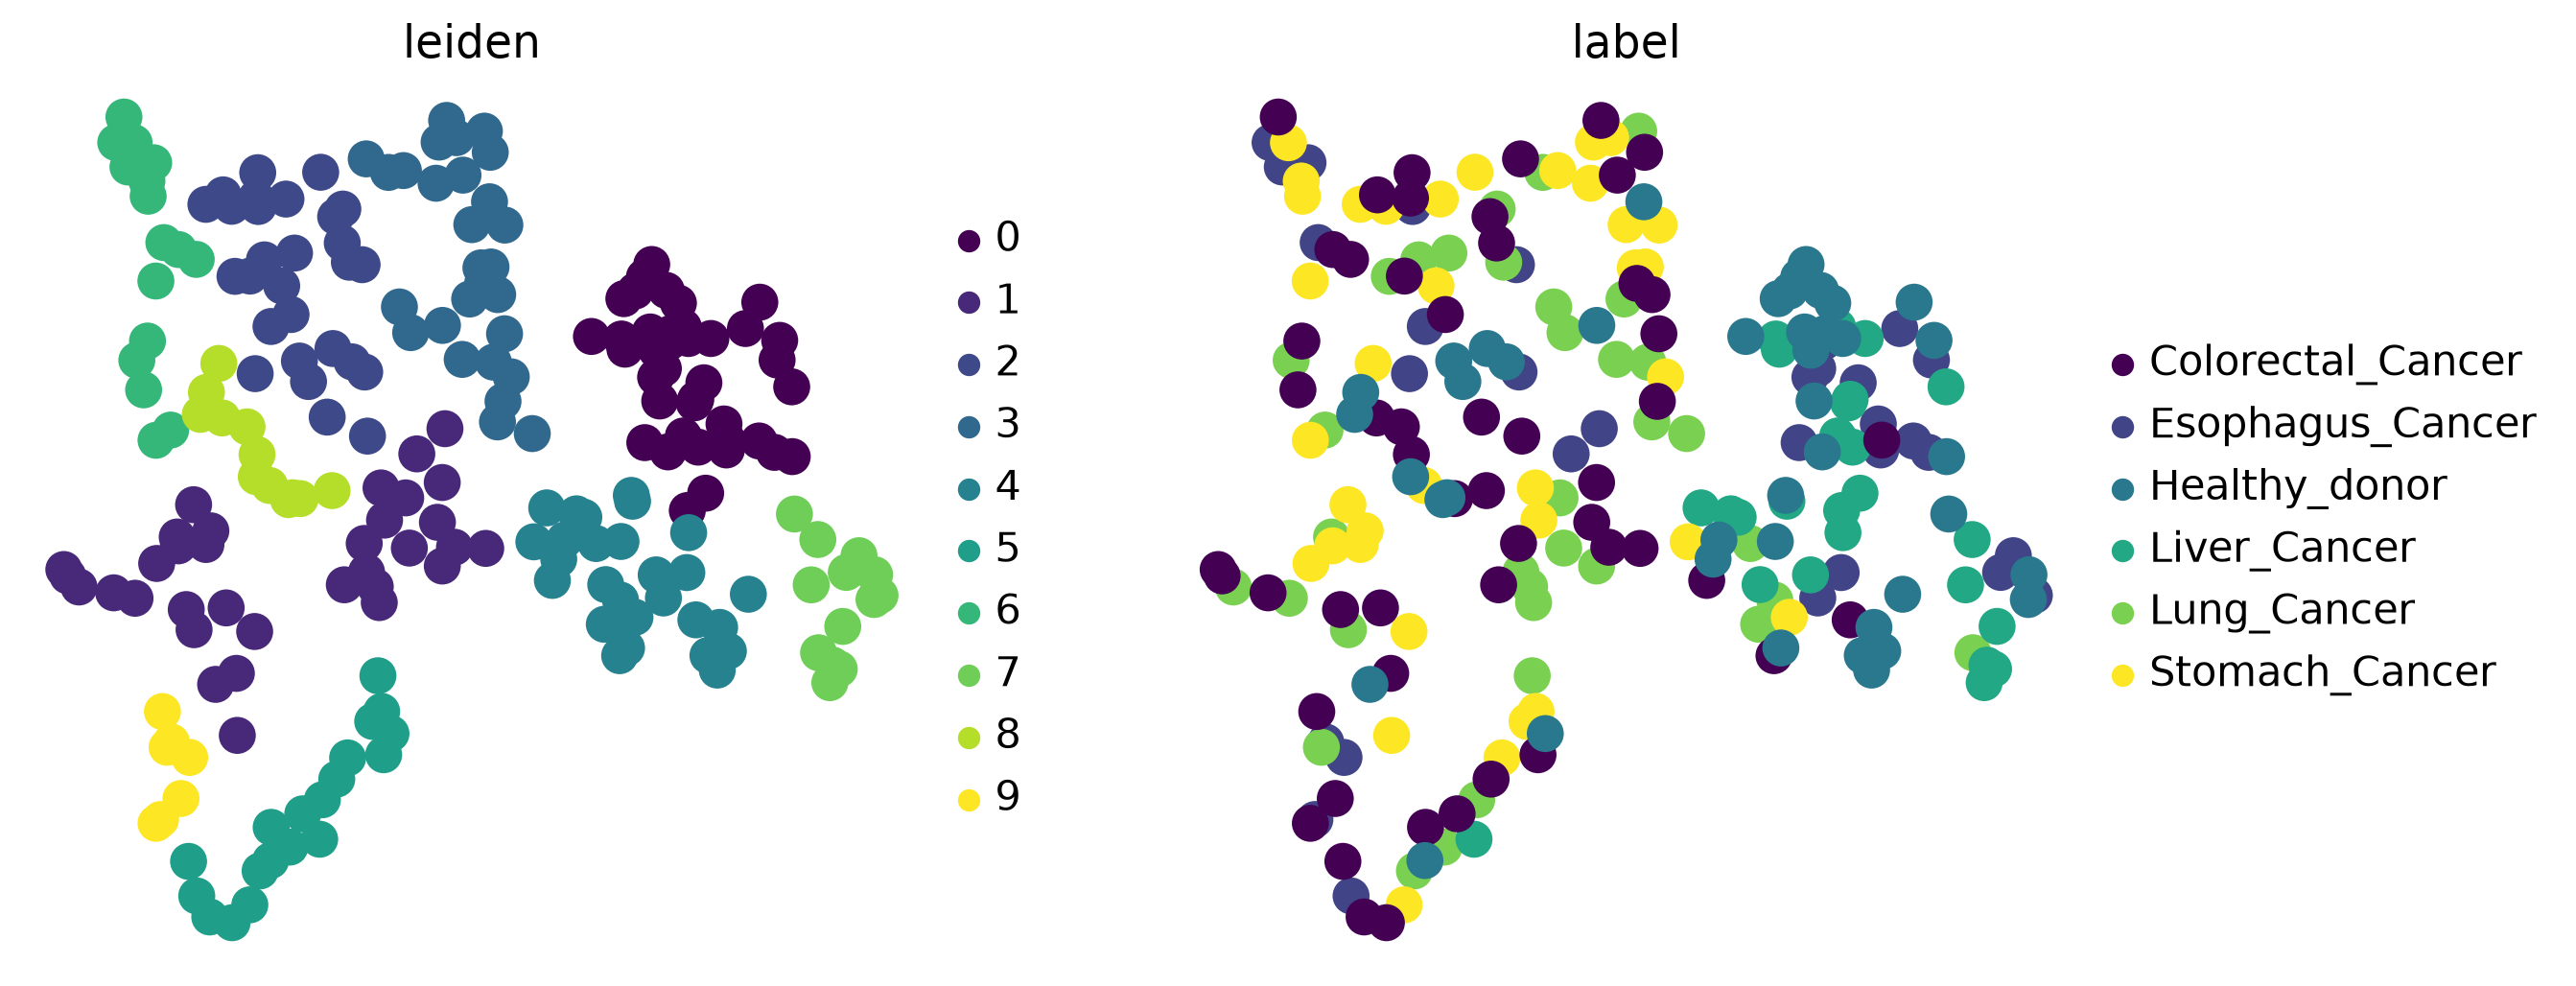

In [26]:
t = runScanpy(principalComponentsNP, 
                realYSeries,
                nNeighbors=3, 
                resolution=0.5,
                plotData=True,
                palette="viridis",
                displayOrSave=False #If true display, if false save
            )

adata, xTabDF, xTabNormalizedDF, _ = t

In [27]:
t = hyperparameterTunning(principalComponentsNP, realYSeries)
bestXTableDF,  bestDict = t
display( bestDict )
display( bestXTableDF)

computing neighbors
    finished (0:00:00)
running Leiden clustering
    finished (0:00:00)
computing UMAP


/private/home/aedavids/graceM/src/python/models/scanpyClustering.py:151: FutureWarning: The argument use_rep is deprecated and will be removed in the future. Use `use` instead.
  sc.pp.neighbors(adata, use_rep="X_pca", n_neighbors=nNeighbors, n_pcs=None)
/private/home/aedavids/graceM/src/python/models/scanpyClustering.py:164: FutureWarning: The argument key_added is deprecated and will be removed in the future. Use `out` instead.
  sc.tl.leiden(adata, resolution=resolution, key_added="leiden")
/private/home/aedavids/miniconda3/envs/graceM/lib/python3.13/site-packages/scverse_misc/_deprecated/__init__.py:117: FutureWarning: The `igraph` and `networkit` implementations of leiden clustering are *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' or 'networkit' to use them.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`.
  return func(

    finished (0:00:00)
computing neighbors
    finished (0:00:00)
running Leiden clustering
    finished (0:00:00)
computing UMAP


/private/home/aedavids/graceM/src/python/models/scanpyClustering.py:151: FutureWarning: The argument use_rep is deprecated and will be removed in the future. Use `use` instead.
  sc.pp.neighbors(adata, use_rep="X_pca", n_neighbors=nNeighbors, n_pcs=None)
/private/home/aedavids/graceM/src/python/models/scanpyClustering.py:164: FutureWarning: The argument key_added is deprecated and will be removed in the future. Use `out` instead.
  sc.tl.leiden(adata, resolution=resolution, key_added="leiden")
/private/home/aedavids/miniconda3/envs/graceM/lib/python3.13/site-packages/scverse_misc/_deprecated/__init__.py:117: FutureWarning: The `igraph` and `networkit` implementations of leiden clustering are *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' or 'networkit' to use them.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`.
  return func(

    finished (0:00:00)
computing neighbors
    finished (0:00:00)
running Leiden clustering
    finished (0:00:00)
computing UMAP


/private/home/aedavids/graceM/src/python/models/scanpyClustering.py:151: FutureWarning: The argument use_rep is deprecated and will be removed in the future. Use `use` instead.
  sc.pp.neighbors(adata, use_rep="X_pca", n_neighbors=nNeighbors, n_pcs=None)
/private/home/aedavids/graceM/src/python/models/scanpyClustering.py:164: FutureWarning: The argument key_added is deprecated and will be removed in the future. Use `out` instead.
  sc.tl.leiden(adata, resolution=resolution, key_added="leiden")
/private/home/aedavids/miniconda3/envs/graceM/lib/python3.13/site-packages/scverse_misc/_deprecated/__init__.py:117: FutureWarning: The `igraph` and `networkit` implementations of leiden clustering are *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' or 'networkit' to use them.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`.
  return func(

... (153 outputs left out)

/private/home/aedavids/graceM/src/python/models/scanpyClustering.py:151: FutureWarning: The argument use_rep is deprecated and will be removed in the future. Use `use` instead.
  sc.pp.neighbors(adata, use_rep="X_pca", n_neighbors=nNeighbors, n_pcs=None)
/private/home/aedavids/graceM/src/python/models/scanpyClustering.py:164: FutureWarning: The argument key_added is deprecated and will be removed in the future. Use `out` instead.
  sc.tl.leiden(adata, resolution=resolution, key_added="leiden")
/private/home/aedavids/miniconda3/envs/graceM/lib/python3.13/site-packages/scverse_misc/_deprecated/__init__.py:117: FutureWarning: The `igraph` and `networkit` implementations of leiden clustering are *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' or 'networkit' to use them.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`.
  return func(

    finished (0:00:00)


{'purity': np.float64(0.38392857142857145),
 'nNeighbors': 3,
 'resolution': np.float64(0.7000000000000001)}

leiden,0,1,2,3,4,5,6,7,8,9,10,11,12
label,,,,,,,,,,,,,
Colorectal_Cancer,1,8,9,3,8,7,0,5,3,3,3,1,2
Esophagus_Cancer,11,0,5,2,2,1,3,0,0,0,3,3,1
Healthy_donor,16,2,4,10,0,2,3,5,0,1,0,0,0
Liver_Cancer,12,0,0,7,0,1,6,0,0,0,0,0,0
Lung_Cancer,0,9,3,3,6,4,1,0,3,3,1,0,2
Stomach_Cancer,0,9,6,2,3,4,0,2,5,2,0,3,0


## <span style="color:red;background-color:yellow;">10/15/26 create final artwork complient figure for manuscript</span>

In [28]:
figureWidthMM = 180
panelAreaHeightMM = 140
legendHeightMM = 12
alpha = 0.5

extF_r2_3Layout: dict[str, Panel] = {
    "a": Panel(
        label="a",
        leftMm=3,
        topMm=3,
        widthMm=86,
        heightMm=65,
    ),
    "b": Panel(
        label="b",
        leftMm=91,
        topMm=3,
        widthMm=86,
        heightMm=65,
    ),
    "c": Panel(
        label="c",
        leftMm=3,
        topMm=72,
        widthMm=86,
        heightMm=65,
    ),
    "d": Panel(
        label="d",
        leftMm=91,
        topMm=72,
        widthMm=86,
        heightMm=65,
    ),
}

In [29]:
finalArtDiagnosisColors: dict[str, str] = {
    "Healthy donor": "#2A788E",
    "Colorectal cancer": "#440154",
    "Esophagus cancer": "#414487",
    "Liver cancer": "#22A884",
    "Lung cancer": "#7AD151",
    "Stomach cancer": "#FDE725",
}

layout[a].widthMm : 86
layout[a].heightMm : 65


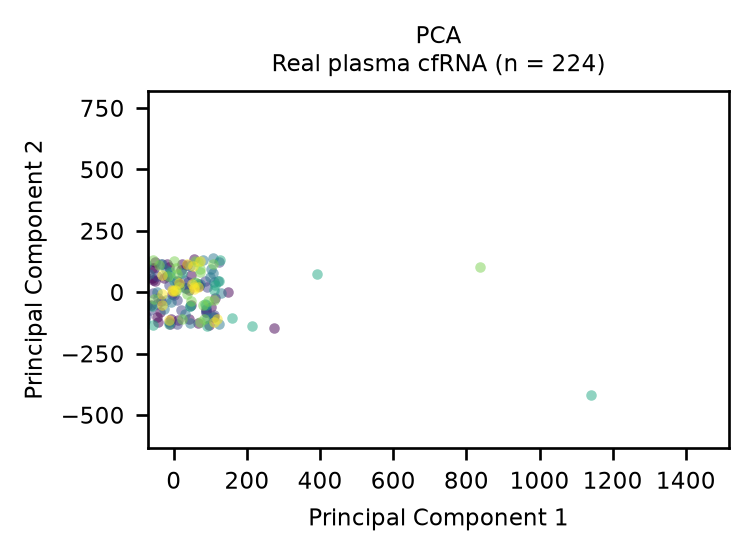

In [30]:
def plotPCAFinalArtwork(
                leftPC : np.array,
                rightPC : np.array,
                panelId : str, 
                fontSize : int = 7,
                markerSize : int=10,
        ) -> None :
    '''
    create 2 plots on the same figure. One using leftPC and rightPC
    
    wrapped this to avoid global polution
    '''
    widthMM, heightMM = getSubplotWidthAndHeight(extF_r2_3Layout, panelId)
    figSize = (widthMM / 25.4, heightMM / 25.4)
    fig, ax = plt.subplots(figsize=figSize)
    # ax1, ax2 = tup
    # markerSize = 10 # 2 #40
    jitterFrac = 0.1 # 10%

    # titleAx1 = f'elife n = {len(realYSeries)}. PCA  n = {leftPC.shape[1]} accounts for {accountForVariance*100:0.2F}% of variance'
    # ax1Jiter = f'jitter={jitterFrac:0.1%}%'
    # titleAx1 = f'{titleAx1} {ax1Jiter}'
    #print(f'{titleAx1}')
    
    title = "PCA\nReal plasma cfRNA (n = 224)"

    pcaScatterPlot( 
            data=leftPC, 
            ySeries=realYSeries,  
            panel=ax,
            title=title,
            markerSize=markerSize,
            jitterFrac=jitterFrac
            )
    
    legend = ax.get_legend()
    legend.remove()
    
    # fix the axis labels
    xLabel = ax.get_xlabel()
    ax.set_xlabel(xLabel, fontsize=fontSize)
 
    yLabel = ax.get_ylabel()
    ax.set_ylabel(yLabel, fontsize=fontSize)
    
    # fix the tick labels
    ax.tick_params(axis="both", which="both", labelsize=7)
       
   
    axTitle = ax.get_title()
    ax.set_title(axTitle, fontsize=fontSize)
    
    # make sure we use the correct fonts
    fontFamily = natureManuscriptStyle["font.family"]
    setFigureFont(fig, fontFamily=fontFamily)  

    fig.tight_layout()
    extF_r2_3Layout[panelId].figure = fig
    
 
        
plotPCAFinalArtwork(
                leftPC=principalComponentsNP,#  : np.array,
                rightPC=bestPCs, # : np.array,
                panelId="a",
                )


layout[b].widthMm : 86
layout[b].heightMm : 65


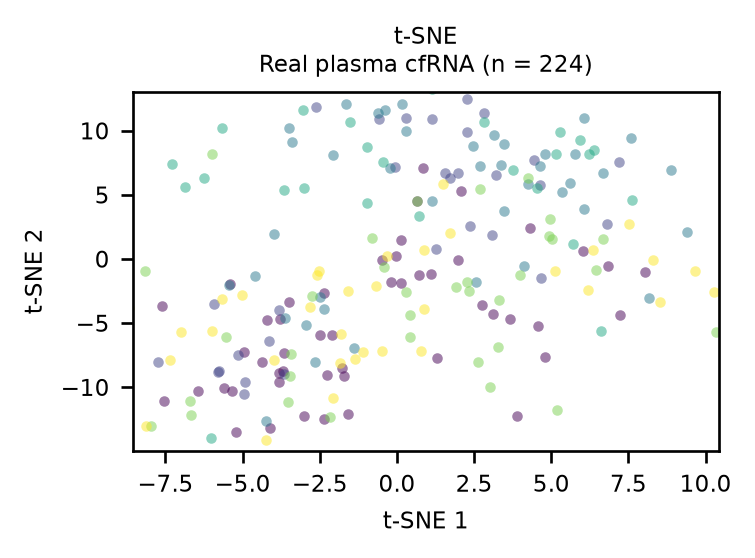

In [31]:
def plotTSNEFinalArtwork(panelId : str,
                         leftPC : np.array,
                        rightPC : np.array,
                        markerSize : int=10,
                        fontSize : int=7
                        ) -> None:
    ''' 
    wrapper to prevent global polution
    '''

    widthMM, heightMM = getSubplotWidthAndHeight(extF_r2_3Layout, panelId)
    figSize = (widthMM / 25.4, heightMM / 25.4)
    fig, ax = plt.subplots(figsize=figSize)
        
    jitterFrac = 0.1 # 10%

    # titleAx1 = f'elife n = {len(realYSeries)}. t-SNE  n = {principalComponentsNP.shape[1]}'
    # ax1Jiter = f'jitter={jitterFrac:0.1%}%'
    # titleAx1 = f'{titleAx1} {ax1Jiter}'
    #print(f'{titleAx1}')
    
    title = "t-SNE\nReal plasma cfRNA (n = 224)"

    tSNEScatterPlot ( 
        data=leftPC, 
        ySeries=realYSeries,  
        panel=ax,
        title=title,
        markerSize=markerSize,
        jitterFrac=jitterFrac
        )
    
    legend = ax.get_legend()
    legend.remove()    
    
    axTitle = ax.get_title()
    ax.set_title(axTitle, fontsize=fontSize)

    # fix the axis labels
    xLabel = ax.get_xlabel()
    ax.set_xlabel(xLabel, fontsize=fontSize)
 
    yLabel = ax.get_ylabel()
    ax.set_ylabel(yLabel, fontsize=fontSize)    
    
    # fix the tick labels
    ax.tick_params(axis="both", which="both", labelsize=7)    
        
    # make sure we use the correct fonts
    fontFamily = natureManuscriptStyle["font.family"]
    setFigureFont(fig, fontFamily=fontFamily)  
        
    fig.tight_layout()
    extF_r2_3Layout[panelId].figure = fig


t = plotTSNEFinalArtwork("b", TSNE_PrincipalComponentsNP, TSNE_BestPCsNP)    

layout[c].widthMm : 86
layout[c].heightMm : 65


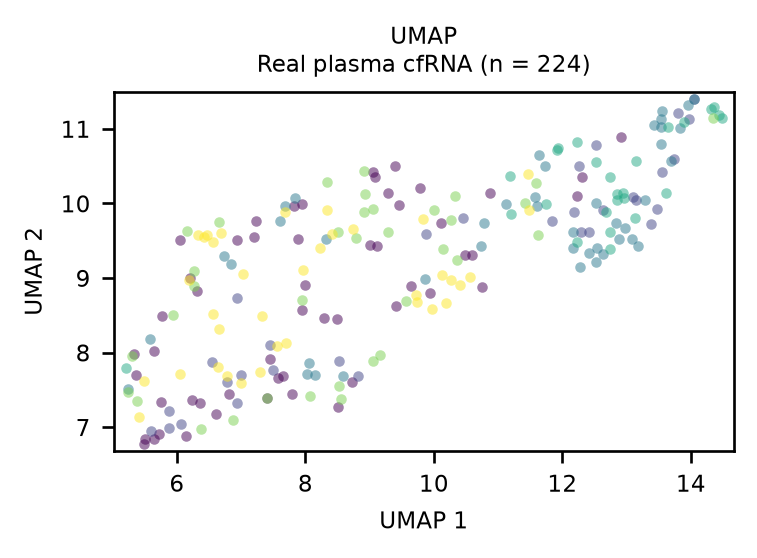

In [32]:
def plotUmapPlotsFinalArt(
                panelId : str,
                leftPC : np.array,
                rightPC : np.array,
                markerSize : int = 10,
                fontSize : int = 7
                ) -> None :
    ''' 
    create 2 plots on the same figure. One using leftPC and rightPC
        
    wrapper to prevent global polution
    '''
    
    widthMM, heightMM = getSubplotWidthAndHeight(extF_r2_3Layout, panelId)
    figSize = (widthMM / 25.4, heightMM / 25.4)
    fig, ax = plt.subplots(figsize=figSize)
      
    jitterFrac = 0 # 0.01 # 1%

    # titleAx = f'elife n = {len(realYSeries)}. UMAP  n = {leftPC.shape[1]}'
    # axJiter = f'jitter={jitterFrac:0.1%}%'
    # titleAx1 = f'{titleAx} {axJiter}'
    #print(f'{titleAx1}')
    
    title = "UMAP\nReal plasma cfRNA (n = 224)"

    umapScatterPlot( 
        data=leftPC, 
        ySeries=realYSeries,  
        panel=ax,
        title=title,
        markerSize=markerSize,
        jitterFrac=jitterFrac
        )
    
    legend = ax.get_legend()
    legend.remove()    
    
    axTitle = ax.get_title()
    ax.set_title(axTitle, fontsize=fontSize)

    # fix the axis labels
    xLabel = ax.get_xlabel()
    ax.set_xlabel(xLabel, fontsize=fontSize)
 
    yLabel = ax.get_ylabel()
    ax.set_ylabel(yLabel, fontsize=fontSize)    
    
    # fix the tick labels
    ax.tick_params(axis="both", which="both", labelsize=7)    
        
    # make sure we use the correct fonts
    fontFamily = natureManuscriptStyle["font.family"]
    setFigureFont(fig, fontFamily=fontFamily)  
        
    fig.tight_layout()
    extF_r2_3Layout[panelId].figure = fig


plotUmapPlotsFinalArt("c", 
                      UMAPEmbeddingPrincipleComponentsNP, 
                      UMAPEmbeddingBestPCsNP,
                      )

computing neighbors
    finished (0:00:00)
running Leiden clustering
    finished (0:00:00)
computing UMAP


/private/home/aedavids/graceM/src/python/models/scanpyClustering.py:151: FutureWarning: The argument use_rep is deprecated and will be removed in the future. Use `use` instead.
  sc.pp.neighbors(adata, use_rep="X_pca", n_neighbors=nNeighbors, n_pcs=None)
/private/home/aedavids/graceM/src/python/models/scanpyClustering.py:164: FutureWarning: The argument key_added is deprecated and will be removed in the future. Use `out` instead.
  sc.tl.leiden(adata, resolution=resolution, key_added="leiden")
/private/home/aedavids/miniconda3/envs/graceM/lib/python3.13/site-packages/scverse_misc/_deprecated/__init__.py:117: FutureWarning: The `igraph` and `networkit` implementations of leiden clustering are *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' or 'networkit' to use them.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`.
  return func(

    finished (0:00:00)
saved /private/home/aedavids/graceM/src/jupyterNotebooks/clusteringWorkflow.out/img/scanpy/leidenUMAP.pdf
saved /private/home/aedavids/graceM/src/jupyterNotebooks/clusteringWorkflow.out/img/scanpy/leidenUMAPLabel.pdf
saved /private/home/aedavids/graceM/src/jupyterNotebooks/clusteringWorkflow.out/img/scanpy/2PlotleidenUMAPLabelFirst.pdf
saved /private/home/aedavids/graceM/src/jupyterNotebooks/clusteringWorkflow.out/img/scanpy/2PlotleidenUMAPLabelSecond.pdf
layout[d].widthMm : 86
layout[d].heightMm : 65


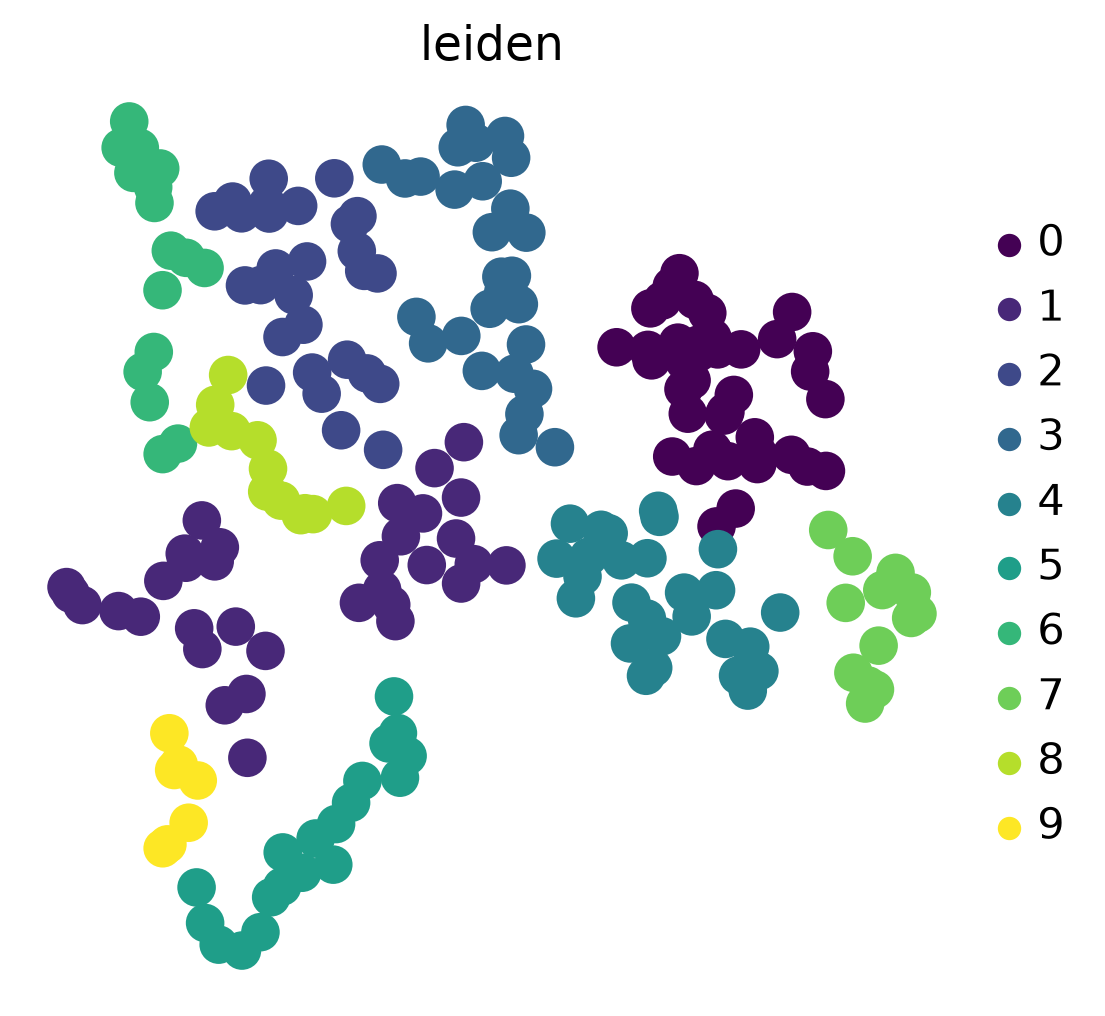

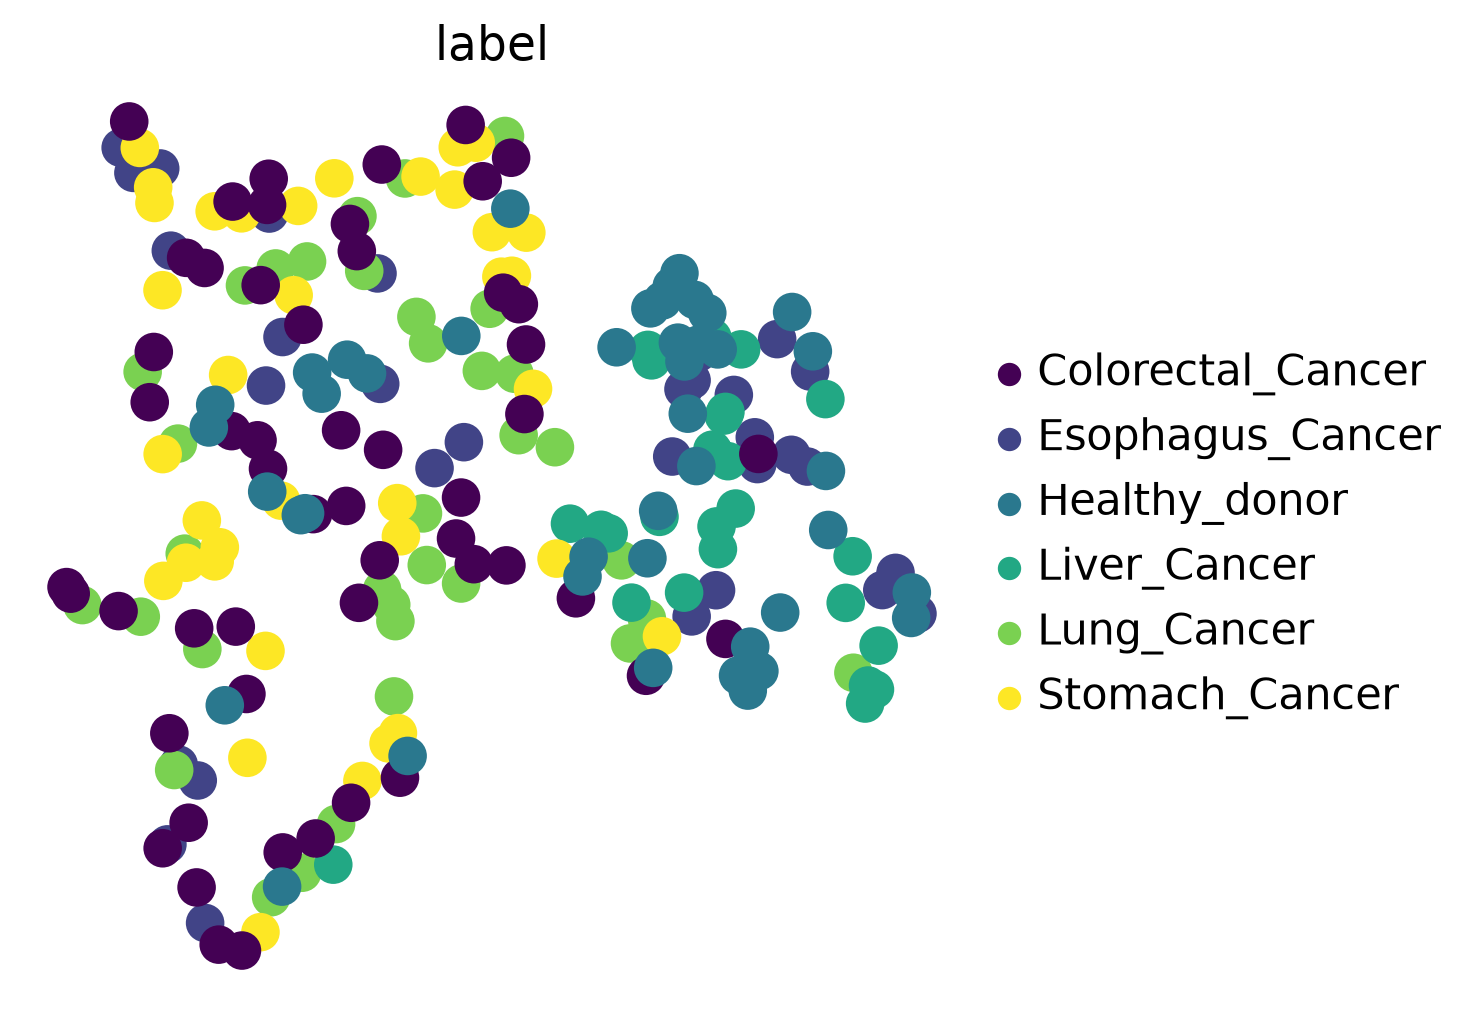

In [33]:
from matplotlib.ticker import MaxNLocator, ScalarFormatter

def plotLeidenFinalArtwork(
                        panelId : str, 
                        markerSize : int = 10,
                        fontSize : int = 7, 
                        ) :
    ''' 
    todo
    '''

    t = runScanpy(principalComponentsNP, 
                    realYSeries,
                    nNeighbors=3, 
                    resolution=0.5,
                    plotData=True,
                    palette="viridis",
                    displayOrSave=False #If true display, if false save
                )

    adata, xTabDF, xTabNormalizedDF, axList = t
    plt.close()
    
    fig = axList[2].get_figure()

    # Keep the right-hand subplot.
    ax = max(fig.axes, key=lambda a: a.get_position().x0)

    for otherAx in list(fig.axes):
        if otherAx is not ax:
            fig.delaxes(otherAx)

    widthMM, heightMM = getSubplotWidthAndHeight(
                                extF_r2_3Layout, panelId
                            )
    fig.set_size_inches(widthMM / 25.4, heightMM / 25.4)

    # Scatter marker area in points squared.
    for collection in ax.collections:
        if hasattr(collection, "set_sizes"):
            collection.set_sizes([markerSize])
            collection.set_alpha(alpha)

    # Remove the subplot legend if using a shared figure legend.
    legend = ax.get_legend()
    if legend is not None:
        legend.remove()

    ax.set_axis_on()
    ax.set_frame_on(True)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(0.5)

    # Restore coordinate ticks and numeric labels.
    ax.xaxis.set_major_locator(MaxNLocator(nbins=7))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=7))

    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.yaxis.set_major_formatter(ScalarFormatter())

    ax.tick_params(
        axis="both",
        which="major",
        bottom=True,
        left=True,
        top=False,
        right=False,
        labelbottom=True,
        labelleft=True,
        direction="out",
        length=3,
        width=0.5,
        labelsize=fontSize,
        pad=2,
    )
    # get rid of the tick grid
    ax.grid(False, which="both", axis="both")
  
    
    # fix the axis labels
    xLabel = ax.get_xlabel()
    ax.set_xlabel(xLabel, fontsize=fontSize)
 
    yLabel = ax.get_ylabel()
    ax.set_ylabel(yLabel, fontsize=fontSize)  
    
    title = "Leiden clustering\nReal plasma cfRNA (n = 224)"
    ax.set_title(title, fontsize=fontSize)
    

    fontFamily = natureManuscriptStyle["font.family"]
    setFigureFont(fig, fontFamily=fontFamily)

    # Expand the retained axes to fill the figure.
    # Do not call tight_layout() afterward.
    fig.set_layout_engine(None)
    ax.set_position([0.08, 0.08, 0.84, 0.84])

    extF_r2_3Layout[panelId].figure = fig  
    
    
        
plotLeidenFinalArtwork("d", markerSize=40)

In [34]:
from matplotlib.lines import Line2D


def plotDiagnosisLegend(
        diagnosisColors: dict[str, str],
        widthMM: float = 180,
        heightMM: float = 15,
        fontSize: float = 7,
        markerSize: float = 4,
        nColumns: int = 3,
    ) -> plt.figure:
    """
    Create a centered legend for the final figure's bottom strip.
    """

    fig = plt.figure(figsize=(widthMM / 25.4, heightMM / 25.4))

    handles = [
        Line2D(
            [],
            [],
            linestyle="none",
            marker="o",
            markersize=markerSize,
            markerfacecolor=color,
            markeredgecolor="none",
            label=diagnosis.replace("_Cancer", "").replace("_", " "),
            alpha=alpha,
        )
        for diagnosis, color in diagnosisColors.items()
    ]

    fig.legend(
        handles=handles,
        loc="center",
        bbox_to_anchor=(0.5, 0.5),
        bbox_transform=fig.transFigure,
        ncol=nColumns,
        frameon=False,
        prop={"family": "Arial", "size": fontSize},
        handletextpad=0.5,
        columnspacing=2,
        labelspacing=0.8,
    )

    fig.tight_layout()
    plt.close(fig)  # Prevent a separate notebook display.
    return fig

In [35]:
# make the margins consitant
for panel in extF_r2_3Layout.values():
    fig = panel.figure

    fig.set_size_inches(
        panel.widthMm / 25.4,
        panel.heightMm / 25.4,
    )

    # Prevent automatic layout from overriding these positions.
    fig.set_layout_engine(None)

    ax = fig.axes[0]

    # [left, bottom, width, height], in figure fractions.
    ax.set_position([0.18, 0.18, 0.79, 0.70])

Layout valid: 180 × 152 mm total; panels occupy extents of 177 × 137 mm.


2026-11-21 11:22:34,003 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 11:22:34,010 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 11:22:34,011 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 11:22:34,012 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 11:22:34,013 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 11:22:34,014 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 11:22:34,015 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 11:22:34,016 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]


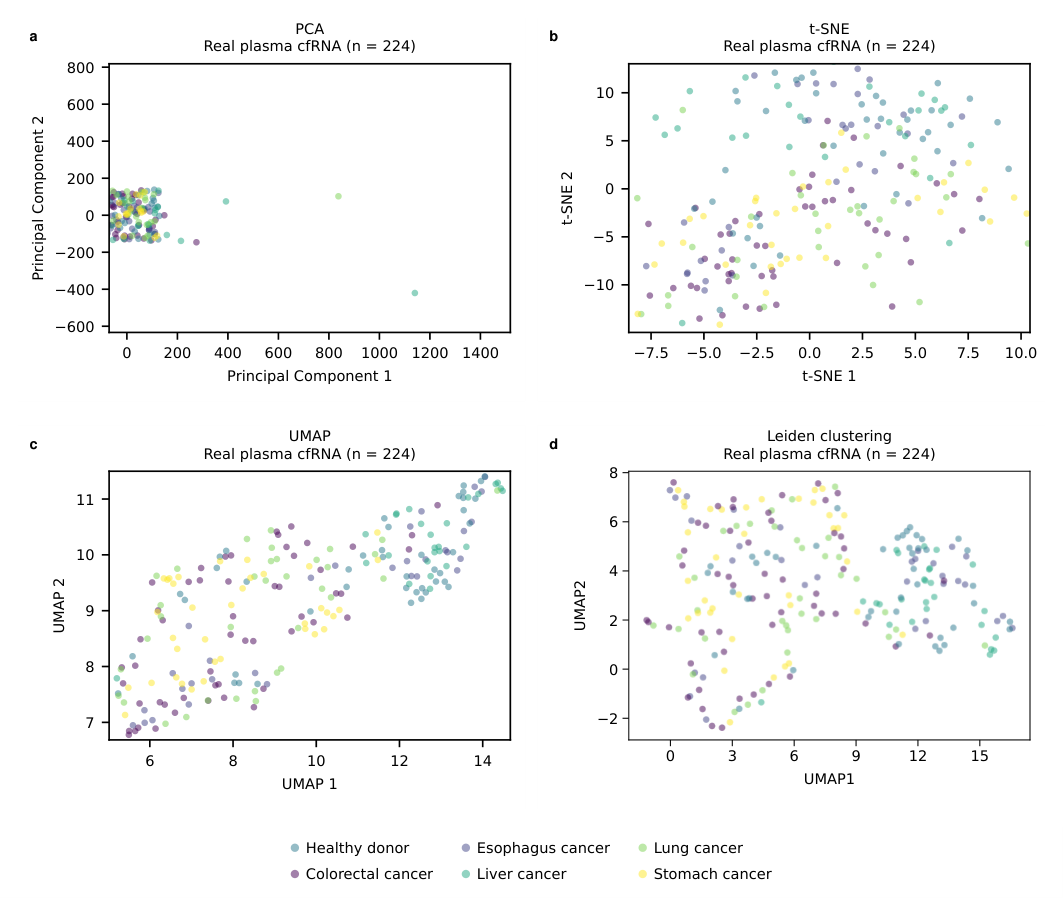

saved : /private/home/aedavids/graceM/src/jupyterNotebooks/clusteringWorkflow.out/img/panel/manuscript/extF_r2_3_clusterPanel.pdf


In [36]:
outputStem = Path(imgPanelOutDir) / "manuscript" / "extF_r2_3_clusterPanel"
outputStem.parent.mkdir(parents=True, exist_ok=True)

legendFig = plotDiagnosisLegend(finalArtDiagnosisColors, heightMM=legendHeightMM)
pdfPath, pngPath = combineFiguresLayout(
    panels=extF_r2_3Layout,
    outputStem=outputStem,
    widthMm=figureWidthMM,
    heightMm=panelAreaHeightMM,
    addPanelLabels=True,
    labelFontSize=7,
    legendFigure=legendFig,
    legendHeightMm=legendHeightMM,
    pngDpi=600,
)

displayPDFInNotebook(pdfPath)

print(f'saved : {pdfPath}')